# HR Analytics | Exploratory Data Analysis
Employee attrition and workforce patterns in the IBM HR Analytics public sample.

**Scope:** descriptive only. Associations here do not explain why an individual leaves, and nothing here should be used to rank or profile employees.
**Input:** `data/processed/hr_employee_clean.csv` (created by `python/01_clean_data.py`).
**Conventions:** segment attrition rate = leavers in segment / employees in segment. Counts are always shown with rates; segments under 30 employees are flagged. This is a single snapshot, not annualized turnover.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)

ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
DATA = ROOT / "data" / "processed" / "hr_employee_clean.csv"
IMG = ROOT / "images"
IMG.mkdir(exist_ok=True)

df = pd.read_csv(DATA)
print(df.shape)
df.head()

(1470, 35)


,age,attrition,business_travel,daily_rate,department,distance_from_home,education,education_field,employee_number,environment_satisfaction,gender,hourly_rate,job_involvement,job_level,job_role,job_satisfaction,marital_status,monthly_income,monthly_rate,num_companies_worked,overtime,percent_salary_hike,performance_rating,relationship_satisfaction,stock_option_level,total_working_years,training_times_last_year,work_life_balance,years_at_company,years_in_current_role,years_since_last_promotion,years_with_curr_manager,attrition_flag,age_band,tenure_band
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,2,Female,94,3,2,Sales Executive,4,Single,5993,19479,8,Yes,11,3,1,0,8,0,1,6,4,0,5,1,35-44,5-9
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,2,3,Male,61,2,2,Research Scientist,2,Married,5130,24907,1,No,23,4,4,1,10,3,3,10,7,1,7,0,45-54,10+
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,4,4,Male,92,2,1,Laboratory Technician,3,Single,2090,2396,6,Yes,15,3,2,0,7,3,3,0,0,0,0,1,35-44,0-1
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,5,4,Female,56,3,1,Research Scientist,3,Married,2909,23159,1,Yes,11,3,3,0,8,3,3,8,7,3,0,0,25-34,5-9
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,7,1,Male,40,3,1,Laboratory Technician,2,Married,3468,16632,9,No,12,3,4,1,6,3,3,2,2,2,2,0,25-34,2-4


## 1. Profile and quality

In [2]:
print("Nulls:", int(df.isna().sum().sum()))
print("Duplicate employee_number:", int(df["employee_number"].duplicated().sum()))
print("Attrition values:", df["attrition"].value_counts().to_dict())
print("Tenure > career length:", int((df["years_at_company"] > df["total_working_years"]).sum()))
df.describe().T[["min", "mean", "max"]].round(2)

Nulls: 0
Duplicate employee_number: 0
Attrition values: {'No': 1233, 'Yes': 237}
Tenure > career length: 0


,min,mean,max
age,18.0,36.92,60.0
daily_rate,102.0,802.49,1499.0
distance_from_home,1.0,9.19,29.0
education,1.0,2.91,5.0
employee_number,1.0,1024.87,2068.0
environment_satisfaction,1.0,2.72,4.0
hourly_rate,30.0,65.89,100.0
job_involvement,1.0,2.73,4.0
job_level,1.0,2.06,5.0
job_satisfaction,1.0,2.73,4.0


## 2. Headline KPIs and reconciliation
These must match the SQL results (`sql/02_kpi_calculations.sql`) and the Power BI cards. Expected values are the SQL results recorded in `documentation/kpi_validation_log.md` for the standard 1,470-row file.

In [3]:
total = len(df)
leavers = int(df["attrition_flag"].sum())
active = total - leavers
rate = round(100 * leavers / total, 2)
retention = round(100 * active / total, 2)

expected = {"total_employees": 1470, "leavers": 237, "active_employees": 1233,
            "attrition_rate_pct": 16.12, "retention_rate_pct": 83.88}
actual = {"total_employees": total, "leavers": leavers, "active_employees": active,
          "attrition_rate_pct": rate, "retention_rate_pct": retention}

recon = pd.DataFrame({"python": actual, "sql_expected": expected})
recon["match"] = recon["python"] == recon["sql_expected"]
display(recon)

print(f"Avg age {df['age'].mean():.1f} | avg tenure {df['years_at_company'].mean():.2f} | avg monthly income {df['monthly_income'].mean():,.0f}")

,python,sql_expected,match
total_employees,1470.00,1470.00,True
leavers,237.00,237.00,True
active_employees,1233.00,1233.00,True
attrition_rate_pct,16.12,16.12,True
retention_rate_pct,83.88,83.88,True


Avg age 36.9 | avg tenure 7.01 | avg monthly income 6,503


## 3. Helpers

In [4]:
MIN_N = 30
OVERALL = 100 * df["attrition_flag"].mean()
AGE_ORDER = ["<25", "25-34", "35-44", "45-54", "55+"]
TENURE_ORDER = ["0-1", "2-4", "5-9", "10+"]


def segment(col, order=None):
    g = df.groupby(col)["attrition_flag"].agg(employees="size", leavers="sum")
    g["attrition_rate_pct"] = (100 * g["leavers"] / g["employees"]).round(2)
    g["share_of_leavers_pct"] = (100 * g["leavers"] / g["leavers"].sum()).round(2)
    g["flag"] = np.where(g["employees"] < MIN_N, "small group", "")
    return g.reindex(order) if order else g.sort_values("attrition_rate_pct", ascending=False)


def plot_rate(g, title, fname):
    fig, ax = plt.subplots(figsize=(8, max(3, 0.45 * len(g) + 1.2)))
    labels = [f"{i} (n={n})" for i, n in zip(g.index.astype(str), g["employees"])]
    ax.barh(labels, g["attrition_rate_pct"], color="#4C78A8")
    ax.axvline(OVERALL, color="#E45756", ls="--", label=f"Overall {OVERALL:.1f}%")
    for y, v in enumerate(g["attrition_rate_pct"]):
        ax.text(v + 0.3, y, f"{v:.1f}%", va="center", fontsize=8)
    ax.invert_yaxis()
    ax.set_xlabel("Attrition rate (%)")
    ax.set_title(title)
    ax.legend(loc="lower right")
    plt.tight_layout()
    fig.savefig(IMG / fname, dpi=150)
    plt.show()

## 4. Segment comparisons
Look at rate **and** headcount: a high rate in a small group can matter less operationally than a moderate rate in a large one.

,employees,leavers,attrition_rate_pct,share_of_leavers_pct,flag
department,,,,,
Sales,446,92,20.63,38.82,
Human Resources,63,12,19.05,5.06,
Research & Development,961,133,13.84,56.12,


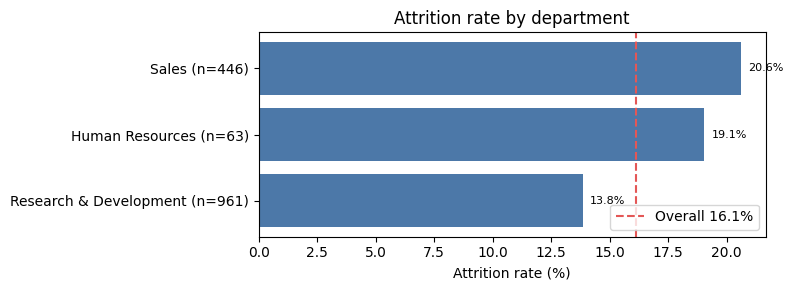

In [5]:
dept = segment("department")
display(dept)
plot_rate(dept, "Attrition rate by department", "eda_department.png")

,employees,leavers,attrition_rate_pct,share_of_leavers_pct,flag
job_role,,,,,
Sales Representative,83,33,39.76,13.92,
Laboratory Technician,259,62,23.94,26.16,
Human Resources,52,12,23.08,5.06,
Sales Executive,326,57,17.48,24.05,
Research Scientist,292,47,16.10,19.83,
Manufacturing Director,145,10,6.90,4.22,
Healthcare Representative,131,9,6.87,3.80,
Manager,102,5,4.90,2.11,
Research Director,80,2,2.50,0.84,


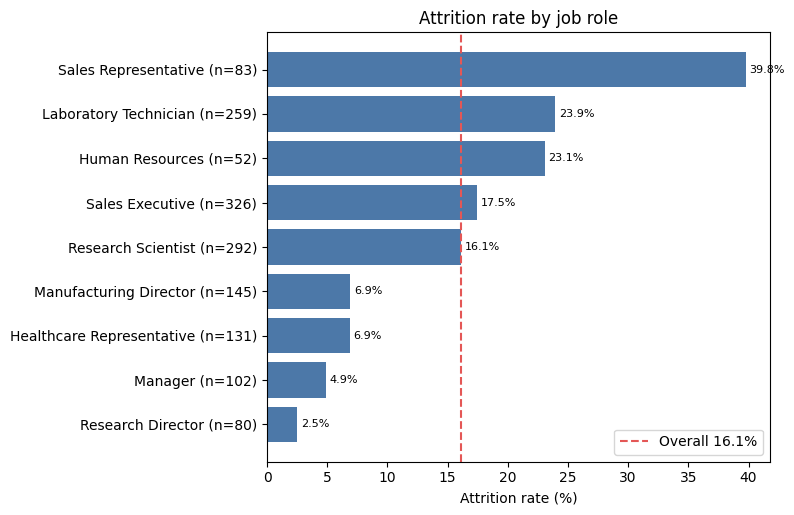

In [6]:
role = segment("job_role")
display(role)
plot_rate(role, "Attrition rate by job role", "eda_job_role.png")

,employees,leavers,attrition_rate_pct,share_of_leavers_pct,flag
overtime,,,,,
Yes,416,127,30.53,53.59,
No,1054,110,10.44,46.41,


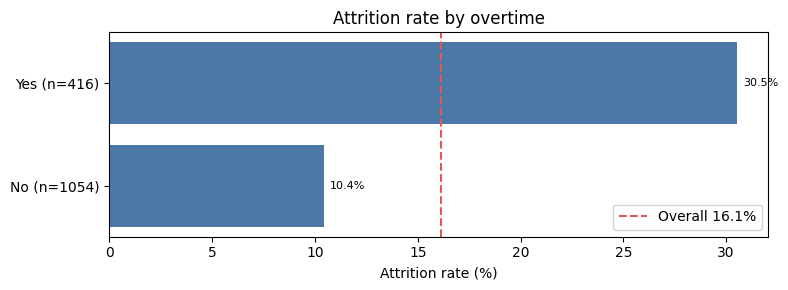

,employees,leavers,attrition_rate_pct,share_of_leavers_pct,flag
business_travel,,,,,
Travel_Frequently,277,69,24.91,29.11,
Travel_Rarely,1043,156,14.96,65.82,
Non-Travel,150,12,8.00,5.06,


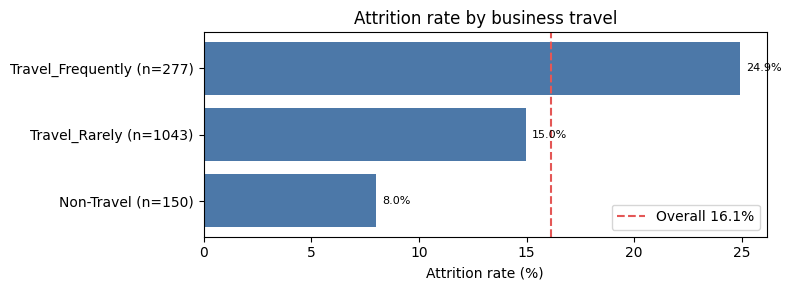

In [7]:
ot = segment("overtime")
display(ot)
plot_rate(ot, "Attrition rate by overtime", "eda_overtime.png")

travel = segment("business_travel")
display(travel)
plot_rate(travel, "Attrition rate by business travel", "eda_travel.png")

,employees,leavers,attrition_rate_pct,share_of_leavers_pct,flag
age_band,,,,,
<25,97,38,39.18,16.03,
25-34,554,112,20.22,47.26,
35-44,505,51,10.10,21.52,
45-54,245,25,10.20,10.55,
55+,69,11,15.94,4.64,


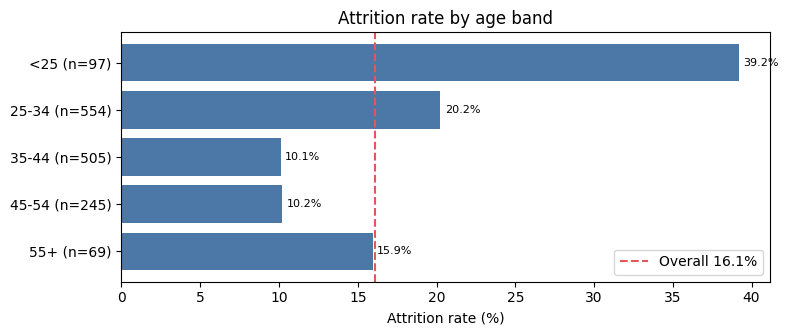

,employees,leavers,attrition_rate_pct,share_of_leavers_pct,flag
tenure_band,,,,,
0-1,215,75,34.88,31.65,
2-4,365,66,18.08,27.85,
5-9,524,58,11.07,24.47,
10+,366,38,10.38,16.03,


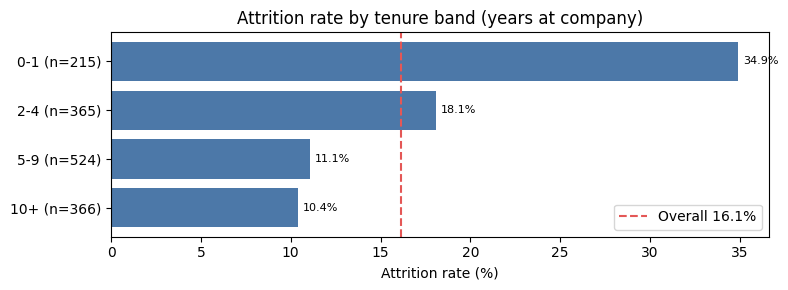

In [8]:
age = segment("age_band", AGE_ORDER)
display(age)
plot_rate(age, "Attrition rate by age band", "eda_age.png")

tenure = segment("tenure_band", TENURE_ORDER)
display(tenure)
plot_rate(tenure, "Attrition rate by tenure band (years at company)", "eda_tenure.png")

,employees,leavers,attrition_rate_pct,share_of_leavers_pct,flag
job_satisfaction,,,,,
1,289,66,22.84,27.85,
2,280,46,16.43,19.41,
3,442,73,16.52,30.80,
4,459,52,11.33,21.94,


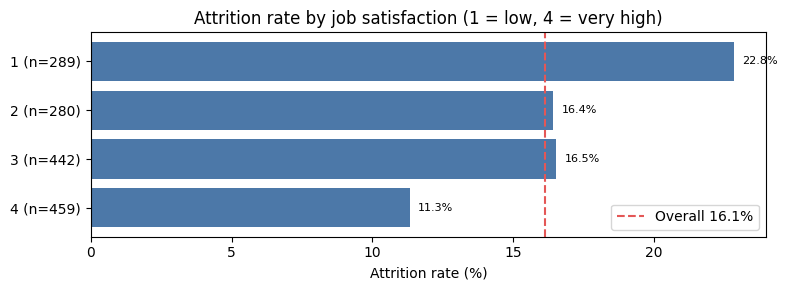

,employees,leavers,attrition_rate_pct,share_of_leavers_pct,flag
work_life_balance,,,,,
1,80,25,31.25,10.55,
2,344,58,16.86,24.47,
3,893,127,14.22,53.59,
4,153,27,17.65,11.39,


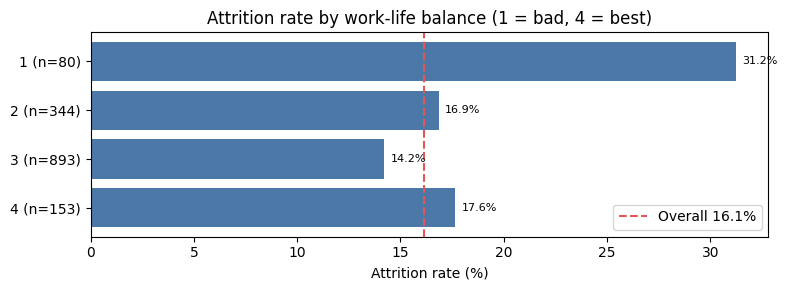

In [9]:
jobsat = segment("job_satisfaction", sorted(df["job_satisfaction"].unique()))
display(jobsat)
plot_rate(jobsat, "Attrition rate by job satisfaction (1 = low, 4 = very high)", "eda_job_satisfaction.png")

wlb = segment("work_life_balance", sorted(df["work_life_balance"].unique()))
display(wlb)
plot_rate(wlb, "Attrition rate by work-life balance (1 = bad, 4 = best)", "eda_work_life_balance.png")

## 5. Leavers vs non-leavers
Averages and distributions. Income and tenure are related to each other and to role and level, so a gap here is a prompt for investigation, not an explanation.

,employees,avg_age,avg_tenure_years,avg_monthly_income,avg_job_satisfaction
attrition,,,,,
No,1233,37.56,7.37,6832.74,2.78
Yes,237,33.61,5.13,4787.09,2.47


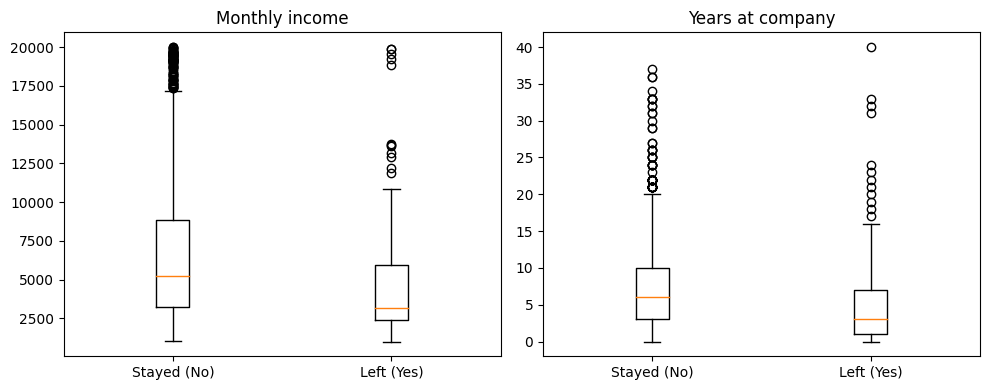

In [10]:
cmp = df.groupby("attrition").agg(
    employees=("attrition", "size"),
    avg_age=("age", "mean"),
    avg_tenure_years=("years_at_company", "mean"),
    avg_monthly_income=("monthly_income", "mean"),
    avg_job_satisfaction=("job_satisfaction", "mean"),
).round(2)
display(cmp)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, col, title in zip(axes, ["monthly_income", "years_at_company"],
                          ["Monthly income", "Years at company"]):
    data = [df.loc[df["attrition"] == s, col] for s in ["No", "Yes"]]
    ax.boxplot(data)
    ax.set_xticks([1, 2], ["Stayed (No)", "Left (Yes)"])
    ax.set_title(title)
plt.tight_layout()
fig.savefig(IMG / "eda_leavers_vs_stayers.png", dpi=150)
plt.show()

## 6. Overlap: does overtime stand on its own?
Reproduces `sql/04_overlap_analysis.sql`. Splits are one variable at a time and not statistically adjusted.

overtime,No,Yes
tenure_band,,
0-1,25.34,55.07
2-4,11.15,35.24
5-9,6.07,24.14
10+,7.81,17.53


overtime,No,Yes
tenure_band,,
0-1,146,69
2-4,260,105
5-9,379,145
10+,269,97


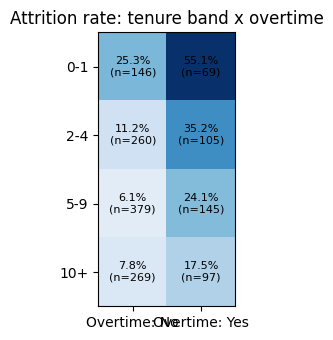

In [11]:
rate_pivot = (df.pivot_table(index="tenure_band", columns="overtime",
                             values="attrition_flag", aggfunc="mean") * 100).reindex(TENURE_ORDER).round(2)
n_pivot = df.pivot_table(index="tenure_band", columns="overtime",
                         values="attrition_flag", aggfunc="size").reindex(TENURE_ORDER)
display(rate_pivot)
display(n_pivot)

fig, ax = plt.subplots(figsize=(5, 3.5))
im = ax.imshow(rate_pivot.values, cmap="Blues", vmin=0)
ax.set_xticks(range(rate_pivot.shape[1]), labels=[f"Overtime: {c}" for c in rate_pivot.columns])
ax.set_yticks(range(rate_pivot.shape[0]), labels=rate_pivot.index)
for i in range(rate_pivot.shape[0]):
    for j in range(rate_pivot.shape[1]):
        ax.text(j, i, f"{rate_pivot.values[i, j]:.1f}%\n(n={n_pivot.values[i, j]})", ha="center", va="center", fontsize=8)
ax.set_title("Attrition rate: tenure band x overtime")
plt.tight_layout()
fig.savefig(IMG / "eda_overtime_by_tenure.png", dpi=150)
plt.show()

In [12]:
by_role = df.pivot_table(index="job_role", columns="overtime", values="attrition_flag",
                         aggfunc=["size", "mean"])
by_role.columns = [f"{'n' if a == 'size' else 'rate_pct'}_ot_{b.lower()}" for a, b in by_role.columns]
for c in [c for c in by_role.columns if c.startswith("rate")]:
    by_role[c] = (100 * by_role[c]).round(2)
by_role["gap_pp"] = (by_role["rate_pct_ot_yes"] - by_role["rate_pct_ot_no"]).round(2)
by_role["flag"] = np.where((by_role["n_ot_yes"] < MIN_N) | (by_role["n_ot_no"] < MIN_N), "small group", "")
by_role.sort_values("gap_pp", ascending=False)

,n_ot_no,n_ot_yes,rate_pct_ot_no,rate_pct_ot_yes,gap_pp,flag
job_role,,,,,,
Sales Representative,59,24,28.81,66.67,37.86,small group
Laboratory Technician,197,62,15.74,50.00,34.26,
Research Scientist,195,97,7.18,34.02,26.84,
Sales Executive,232,94,11.21,32.98,21.77,
Human Resources,39,13,17.95,38.46,20.51,small group
Manager,75,27,1.33,14.81,13.48,small group
Manufacturing Director,106,39,5.66,10.26,4.60,
Research Director,57,23,1.75,4.35,2.60,small group
Healthcare Representative,94,37,7.45,5.41,-2.04,


In [13]:
df["tenure_group"] = np.where(df["years_at_company"] < 5, "Under 5 yrs", "5+ yrs")
df["travel_group"] = np.where(df["business_travel"] == "Travel_Frequently", "Frequent travel", "Other travel")
three = df.groupby(["overtime", "tenure_group", "travel_group"])["attrition_flag"].agg(
    employees="size", leavers="sum")
three["attrition_rate_pct"] = (100 * three["leavers"] / three["employees"]).round(2)
three["share_of_employees_pct"] = (100 * three["employees"] / three["employees"].sum()).round(2)
three["share_of_leavers_pct"] = (100 * three["leavers"] / three["leavers"].sum()).round(2)
three["flag"] = np.where(three["employees"] < MIN_N, "small group", "")
three.sort_values("attrition_rate_pct", ascending=False)

employees  leavers  attrition_rate_pct  share_of_employees_pct  share_of_leavers_pct flag
overtime tenure_group travel_group                                                                                              
Yes      Under 5 yrs  Frequent travel         36       22               61.11                    2.45                  9.28     
                      Other travel           138       53               38.41                    9.39                 22.36     
No       Under 5 yrs  Frequent travel         73       21               28.77                    4.97                  8.86     
Yes      5+ yrs       Frequent travel         50       14               28.00                    3.40                  5.91     
                      Other travel           192       38               19.79                   13.06                 16.03     
No       Under 5 yrs  Other travel           333       45               13.51                   22.65                 18.99     
         5+ yrs       Frequent travel        118       12               10.17                    8.03                  5.06     
                      Other travel           530       32                6.04                   36.05                 13.50

## 7. Small-group check and reconciliation

In [14]:
cell = df.groupby(["department", "job_role"])["attrition_flag"].agg(employees="size", leavers="sum")
cell["attrition_rate_pct"] = (100 * cell["leavers"] / cell["employees"]).round(2)
print("Department x role cells under 30 employees (qualify any conclusions):")
display(cell[cell["employees"] < MIN_N])

assert dept["employees"].sum() == total and role["employees"].sum() == total
assert dept["leavers"].sum() == leavers and role["leavers"].sum() == leavers
print("Segment totals reconcile to overall employees and leavers.")

Department x role cells under 30 employees (qualify any conclusions):


,,employees,leavers,attrition_rate_pct
department,job_role,,,
Human Resources,Manager,11,0,0.0


Segment totals reconcile to overall employees and leavers.


## 8. Notes
- Descriptive snapshot of a public sample; no time dimension and no causal claims.
- Overtime shows the largest gap, and it persists within tenure, age, travel, department and (for most roles) job role groups. Other unmeasured factors cannot be ruled out.
- Several scale fields (satisfaction, work-life balance) are not monotonic; smaller groups are less stable.
- Charts are saved to `images/` for the README and the insights report.